# Лабораторная работа 4. Сеть Колмогорова–Арнольда

*Цифровое приложение 2 к главе 4 пособия «Нейронные сети для инженеров»*

**Цель работы** — построить сеть Колмогорова–Арнольда (KAN) со сплайновыми функциями на связях, проверить точное представление произведения, обучить сеть на данных ультразвукового расходомера, интерпретировать полученные функции и сравнить сеть с многослойным перцептроном при близком числе параметров.

**Физическая постановка** (п. 4.4.1). Вклад одной хорды многоплоскостного расходомера (3.12) пропорционален отношению $\Delta t/\sigma_t^2$ разности и квадрата суммы времён пролёта. В безразмерных величинах $u=\Delta t/\Delta t_{\max}\in[0{,}1;\,1]$ и $v=\sigma_t/\sigma_{t,0}\in[0{,}8;\,1{,}2]$ сеть должна восстановить зависимость

$$y=\frac{u}{v^2}. \tag{4.32}$$

Формулу мы знаем, но сеть получает только пары «вход — выход». Входы нормируются на отрезок сетки:
$\tilde u = 2(u-0{,}1)/0{,}9-1,\quad \tilde v=(v-1)/0{,}2.$  (4.33)

**Файлы.** Реализация сети — модуль `kan.py` в этой же папке. Общие данные для Engee, MATLAB и Python — `data/lab04_samples.csv` и `data/lab04_initial.csv`; если файлов нет, блокнот создаёт их сам. Результаты сохраняются в папку `results/`. Нужны NumPy и Matplotlib; полный прогон занимает около минуты.

**Порядок выполнения**
1. [Подготовка данных и моделей](#s1)
2. [B-сплайны и разбиение единицы](#s2) — п. 4.4.2
3. [Синтез сети 2–2–1 для произведения](#s3) — п. 4.4.3
4. [Обучение сети 2–1–1 и сравнение с перцептронами](#s4) — п. 4.4.4
5. [Символизация функций на связях](#s5) — п. 4.4.5
6. [Экстраполяция](#s6) — п. 4.4.6
7. [Опыт с шумом](#s7) — п. 4.4.6
8. [Сохранение результатов и отчёт](#s8) — п. 4.4.7

<a id="s1"></a>
## 1. Подготовка данных и моделей

In [1]:
import os, csv, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch
from IPython.display import Markdown, display

from kan import KAN, train, check_gradients, bspline, knots, silu

# оформление рисунков как в пособии: чёрно-белые, шрифты STIX, десятичная запятая
plt.rcParams.update({'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 10,
                     'axes.linewidth': 0.7, 'legend.frameon': False, 'figure.dpi': 110})
_sf = mticker.ScalarFormatter.__call__
mticker.ScalarFormatter.__call__ = lambda self, x, pos=None: _sf(self, x, pos).replace('.', ',')
GREY = '0.92'
STYLES = [dict(color='black', ls='-'), dict(color='0.5', ls='-', lw=1.6),
          dict(color='black', ls='--'), dict(color='black', ls=':'), dict(color='black', ls='-.')]

num = lambda v, d=3: f'{v:.{d}g}'.replace('.', ',')
sci = lambda v: (lambda m, e: f'${m.replace(".", "{,}")}\\cdot10^{{{int(e)}}}$')(*f'{v:.2e}'.split('e'))

DATA_DIR, RES_DIR = 'data', 'results'
SAMPLES, INITIAL = f'{DATA_DIR}/lab04_samples.csv', f'{DATA_DIR}/lab04_initial.csv'
SEED_DATA, SEED_INIT, SEED_NOISE = 20261007, 1, 314159
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

Для сравнения нужен многослойный перцептрон с активацией $\tanh$ в скрытом слое и линейным выходом. Он не входит в модуль `kan.py`, поэтому определим его здесь. У него те же методы `forward`, `backward` и `params`, что у сети KAN, поэтому функция `train` из модуля работает с ним без изменений.

In [2]:
class MLP:
    # перцептрон: tanh в скрытых слоях, линейный выход; число параметров по формуле (4.22)
    def __init__(self, sizes):
        self.sizes = sizes
        self.W = [np.zeros((b, a)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]

    def forward(self, X):
        self.h = [X]
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            Z = X @ W.T + b
            X = np.tanh(Z) if l < len(self.W) - 1 else Z
            self.h.append(X)
        return X

    predict = forward

    def backward(self, D):
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in reversed(range(len(self.W))):
            if l < len(self.W) - 1:
                D = D * (1 - self.h[l + 1] ** 2)
            gW[l] = D.T @ self.h[l]
            gb[l] = D.sum(0)
            D = D @ self.W[l]
        return [g for pair in zip(gW, gb) for g in pair]

    def params(self):
        return [p for pair in zip(self.W, self.b) for p in pair]

    def n_params(self):
        return sum(p.size for p in self.params())

**Общие файлы.** Данные: 400 обучающих, 100 валидационных, 200 тестовых примеров с независимыми равномерно распределёнными $u$ и $v$, а также 200 примеров для экстраполяции с $u\in[1;\,1{,}3]$. Начальные значения параметров: $c_m\sim\mathcal N(0;\,0{,}1)$, $w_b\sim\mathcal N(0;\,1/\sqrt{n_{l-1}})$, $w_s=1$; у перцептрона $W\sim\mathcal N(0;\,1/\sqrt{n_{\mathrm{in}}})$, $b=0$. Для воспроизведения результатов в разных средах используются именно эти файлы, а не повторная генерация.

In [3]:
def write_csv(path, header, rows):
    with open(path, 'w', newline='', encoding='utf-8') as f:
        w = csv.writer(f); w.writerow(header)
        for r in rows:
            w.writerow([f'{x:.17g}' if isinstance(x, float) else x for x in r])

def normalize(u, v):
    return np.stack([2 * (u - 0.1) / 0.9 - 1, (v - 1) / 0.2], axis=1)      # (4.33)

def target(u, v):
    return (u / v ** 2)[:, None]                                         # (4.32)

MODELS = {'KAN 2-1-1 G=5': lambda: KAN([2, 1, 1], G=5),
          'MLP 2-7-1':     lambda: MLP([2, 7, 1]),
          'MLP 2-20-1':    lambda: MLP([2, 20, 1])}

def initial_values(model):
    rng = np.random.default_rng(SEED_INIT)
    if isinstance(model, KAN):
        for L in model.layers:
            L.c[...] = rng.normal(0, 0.1, L.c.shape)
            L.wb[...] = rng.normal(0, 1.0 / np.sqrt(L.nin), L.wb.shape)
            L.ws[...] = 1.0
    else:
        for W, b in zip(model.W, model.b):
            W[...] = rng.normal(0, 1.0 / np.sqrt(W.shape[1]), W.shape); b[...] = 0.0

if not os.path.exists(SAMPLES):
    rng = np.random.default_rng(SEED_DATA); rows = []
    for part, n, (lo, hi) in [(1, 400, (0.1, 1.0)), (2, 100, (0.1, 1.0)), (3, 200, (0.1, 1.0)), (4, 200, (1.0, 1.3))]:
        u = rng.uniform(lo, hi, n); v = rng.uniform(0.8, 1.2, n)
        rows += [(part, float(a), float(b), float(a / b ** 2)) for a, b in zip(u, v)]
    write_csv(SAMPLES, ['part', 'u', 'v', 'y'], rows); print('создан', SAMPLES)
if not os.path.exists(INITIAL):
    rows = []
    for name, make in MODELS.items():
        m = make(); initial_values(m)
        rows += [(name, a, n, float(x)) for a, p in enumerate(m.params()) for n, x in enumerate(p.ravel())]
    write_csv(INITIAL, ['model', 'array', 'index', 'value'], rows); print('создан', INITIAL)

data = np.genfromtxt(SAMPLES, delimiter=',', skip_header=1)
D = {}
for code_, name in [(1, 'train'), (2, 'val'), (3, 'test'), (4, 'extra')]:
    d = data[data[:, 0] == code_]
    D[name] = (normalize(d[:, 1], d[:, 2]), d[:, 3:4], d[:, 1], d[:, 2])

with open(INITIAL, encoding='utf-8') as f:
    INIT_ROWS = list(csv.reader(f))[1:]
def load_initial(name):
    m = MODELS[name](); params = m.params()
    for model, a, n, val in INIT_ROWS:
        if model == name: params[int(a)].flat[int(n)] = float(val)
    return m

display(Markdown('| Часть | Примеров | $u$ | $v$ |\n|---|---|---|---|\n' + ''.join(
    f'| {lab} | {len(D[k][1])} | {num(D[k][2].min())} … {num(D[k][2].max())} | {num(D[k][3].min())} … {num(D[k][3].max())} |\n'
    for k, lab in [('train', 'обучение'), ('val', 'валидация'), ('test', 'тест'), ('extra', 'экстраполяция')])))

| Часть | Примеров | $u$ | $v$ |
|---|---|---|---|
| обучение | 400 | 0,1 … 0,999 | 0,802 … 1,2 |
| валидация | 100 | 0,103 … 0,989 | 0,802 … 1,2 |
| тест | 200 | 0,107 … 0,984 | 0,803 … 1,2 |
| экстраполяция | 200 | 1 … 1,3 | 0,801 … 1,19 |


<a id="s2"></a>
## 2. B-сплайны и разбиение единицы (п. 4.4.2)

Функция `bspline` реализует формулы Кокса–де Бура (4.12)–(4.13) и возвращает матрицу: строка — точка $x$, столбец — базисная функция. На отрезке $[a,b]$ сумма всех функций равна единице. На равномерной сетке (4.11) оба знаменателя в (4.13) равны $kh>0$, поэтому деления на нуль не возникает.

кубических функций: 8, отклонение суммы от 1: 2.2e-16


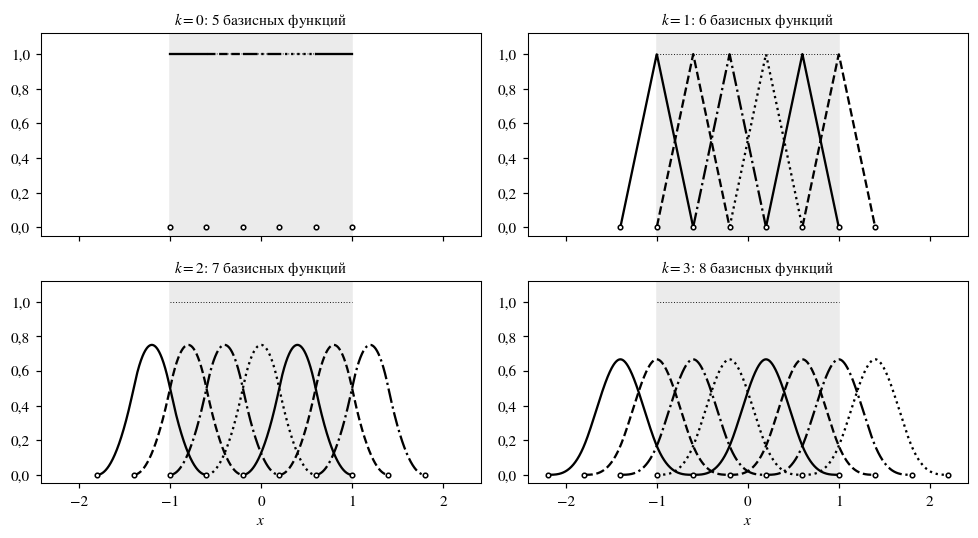

In [4]:
t = knots(-1.0, 1.0, 5, 3)
B = bspline(np.linspace(-1.0, 1.0, 201), t, 3)
assert B.shape[1] == 8 and np.max(np.abs(B.sum(axis=1) - 1)) < 1e-12
print(f'кубических функций: {B.shape[1]}, отклонение суммы от 1: {np.max(np.abs(B.sum(axis=1) - 1)):.1e}')

fig, axs = plt.subplots(2, 2, figsize=(9, 5), sharex=True)
for k, ax in zip(range(4), axs.flat):
    tk = knots(-1, 1, 5, k); xs = np.linspace(tk[0], tk[-1] - 1e-9, 1201); Bk = bspline(xs, tk, k)
    for m in range(Bk.shape[1]):
        supp = (xs >= tk[m]) & (xs <= tk[m + k + 1])
        ax.plot(xs[supp], Bk[supp, m], **STYLES[[0, 2, 4, 3][m % 4]])
    inside = (xs >= -1) & (xs < 1)
    ax.plot(xs[inside], Bk[inside].sum(1), color='black', lw=0.6, ls=(0, (1, 2)))
    ax.axvspan(-1, 1, color=GREY, zorder=0)
    ax.plot(tk, np.zeros_like(tk), 'o', ms=3, mfc='white', mec='black', clip_on=False, zorder=5)
    ax.set_title(f'$k={k}$: {5 + k} базисных функций', fontsize=10); ax.set_ylim(-0.05, 1.12)
for ax in axs[1]: ax.set_xlabel('$x$')
fig.tight_layout(); fig.savefig(f'{RES_DIR}/bsplines.png', dpi=200); plt.show()

**Задание.** Аппроксимация $e^x$ на $[-1,1]$ кубическим сплайном по 41 узлу при $G=2,4,8$ — это линейная задача МНК $\mathbf c=V\backslash\mathbf y$ (3.6). Сравните ошибку с полиномом Тейлора из примера 3.2 (равномерная ошибка $e-8/3\approx0{,}0516$).

In [5]:
x = np.linspace(-1, 1, 41); xd = np.linspace(-1, 1, 2001)[:-1]
rows = ''
for G in (2, 4, 8):
    tk = knots(-1, 1, G, 3)
    c = np.linalg.lstsq(bspline(x, tk, 3), np.exp(x), rcond=None)[0]
    rows += f'| {G} | {G + 3} | {sci(np.max(np.abs(bspline(xd, tk, 3) @ c - np.exp(xd))))} |\n'
display(Markdown('| $G$ | Коэффициентов | Макс. ошибка |\n|---|---|---|\n' + rows))

| $G$ | Коэффициентов | Макс. ошибка |
|---|---|---|
| 2 | 5 | $1{,}78\cdot10^{-3}$ |
| 4 | 7 | $1{,}22\cdot10^{-4}$ |
| 8 | 11 | $1{,}07\cdot10^{-5}$ |


При удвоении $G$ ошибка уменьшается примерно в $2^4=16$ раз: для кубического сплайна погрешность пропорциональна $h^4$.

<a id="s3"></a>
## 3. Синтез сети 2–2–1 для произведения (п. 4.4.3)

Как и в главе 2, начинаем с **синтеза**: функции на связях берутся из известной формулы (4.3) $xy=\tfrac14(x+y)^2-\tfrac14(x-y)^2$. Все функции — полиномы степени не выше 2, а кубический сплайн воспроизводит их точно, поэтому коэффициенты каждой связи находятся одной операцией МНК.

In [6]:
def fit_edge(f, a, b, G=4, k=3):
    tk = knots(a, b, G, k); xs = np.linspace(a, b, 50)
    c = np.linalg.lstsq(bspline(xs, tk, k), f(xs), rcond=None)[0]       # аналог c = V \ y
    return lambda x: bspline(x, tk, k) @ c

phi11, phi12 = fit_edge(lambda x: x, 0, 1), fit_edge(lambda y: y, 0, 1)
phi21, phi22 = fit_edge(lambda x: x, 0, 1), fit_edge(lambda y: -y, 0, 1)
Phi1, Phi2 = fit_edge(lambda s: s ** 2 / 4, 0, 2), fit_edge(lambda s: -s ** 2 / 4, -1, 1)

rng = np.random.default_rng(0); xs_, ys_ = rng.random(1000), rng.random(1000)
z = Phi1(phi11(xs_) + phi12(ys_)) + Phi2(phi21(xs_) + phi22(ys_))
err = np.max(np.abs(z - xs_ * ys_)); assert err < 1e-10
print(f'максимальная ошибка на 1000 случайных точках: {err:.1e}  (только округление)')

максимальная ошибка на 1000 случайных точках: 1.3e-15  (только округление)


Сетки внешних функций выбраны по диапазонам внутренних сумм: $s_1=x+y\in[0,2]$, $s_2=x-y\in[-1,1]$.

<a id="s4"></a>
## 4. Обучение сети 2–1–1 и сравнение с перцептронами (п. 4.4.4)

Сначала проверим градиенты обратного прохода (4.24)–(4.26) сравнением с конечными разностями.

In [7]:
g = check_gradients(load_initial('KAN 2-1-1 G=5'), *D['train'][:2])
assert g < 1e-6
print(f'наибольшее относительное расхождение с конечными разностями: {g:.1e}')

наибольшее относительное расхождение с конечными разностями: 5.6e-08


**Настройки обучения.** Метод Adam, полный пакет; сохраняется состояние с наименьшей валидационной ошибкой, тестовая выборка в выборе не участвует.

| Модель | Этапы |
|---|---|
| KAN 2–1–1, $G=5$ | 3000 эпох, шаг 0,01 |
| KAN 2–1–1, $G=5\to10\to20$ | 3000 эпох (0,01) → обновление сетки (4.27), $G=10$, 1500 эпох (0,003) → $G=20$, 1500 эпох (0,001) |
| MLP 2–7–1 и 2–20–1 | 6000 эпох, шаг 0,01 |

In [8]:
def run_model(init_name, D, stages, history):
    m = load_initial(init_name); t0 = time.perf_counter()
    for st in stages:
        if 'G' in st: m.update_grid(D['train'][0], st['G'])
        train(m, *D['train'][:2], *D['val'][:2], st['epochs'], st['lr'], history)
    return m, time.perf_counter() - t0

def metrics(model, X, y):
    e = model.predict(X) - y
    return np.sqrt(np.mean(e ** 2)), np.mean(np.abs(e)), np.max(np.abs(e))

STAGED = [dict(epochs=3000, lr=0.01), dict(G=10, epochs=1500, lr=0.003), dict(G=20, epochs=1500, lr=0.001)]
PLANS = [('KAN 2–1–1, $G=5$',            'KAN 2-1-1 G=5', [dict(epochs=3000, lr=0.01)]),
         ('KAN 2–1–1, $G=5\\to10\\to20$', 'KAN 2-1-1 G=5', STAGED),
         ('MLP 2–7–1',                    'MLP 2-7-1',     [dict(epochs=6000, lr=0.01)]),
         ('MLP 2–20–1',                   'MLP 2-20-1',    [dict(epochs=6000, lr=0.01)])]
models, hists, rows_metrics = {}, {}, []
for label, init_name, stages in PLANS:
    h = []; m, sec = run_model(init_name, D, stages, h)
    models[label], hists[label] = m, h
    te, ex = metrics(m, *D['test'][:2]), metrics(m, *D['extra'][:2])
    rows_metrics.append((label, m.n_params(), *te, *ex, sec))
    print(f'{label.replace("$", "").replace(chr(92) + "to", "→"):24s} обучено за {sec:.1f} с')

display(Markdown('**Таблица 4.3.** Ошибки на 200 тестовых примерах и на 200 примерах экстраполяции\n\n'
    '| Модель | Парам. | RMSE, тест | MAE, тест | Макс., тест | RMSE, экстр. | Макс., экстр. | Время, с |\n'
    '|---|---|---|---|---|---|---|---|\n' + ''.join(
    f'| {r[0]} | {r[1]} | {sci(r[2])} | {sci(r[3])} | {sci(r[4])} | {num(r[5])} | {num(r[7])} | {num(r[8], 2)} |\n'
    for r in rows_metrics)))

KAN 2–1–1, G=5           обучено за 7.7 с
KAN 2–1–1, G=5→10→20     обучено за 17.3 с
MLP 2–7–1                обучено за 2.6 с
MLP 2–20–1               обучено за 5.5 с


**Таблица 4.3.** Ошибки на 200 тестовых примерах и на 200 примерах экстраполяции

| Модель | Парам. | RMSE, тест | MAE, тест | Макс., тест | RMSE, экстр. | Макс., экстр. | Время, с |
|---|---|---|---|---|---|---|---|
| KAN 2–1–1, $G=5$ | 30 | $2{,}09\cdot10^{-4}$ | $1{,}55\cdot10^{-4}$ | $8{,}38\cdot10^{-4}$ | 0,0307 | 0,0814 | 7,7 |
| KAN 2–1–1, $G=5\to10\to20$ | 75 | $3{,}19\cdot10^{-6}$ | $1{,}44\cdot10^{-6}$ | $2{,}43\cdot10^{-5}$ | 0,182 | 0,361 | 17 |
| MLP 2–7–1 | 29 | $1{,}69\cdot10^{-3}$ | $1{,}26\cdot10^{-3}$ | $6{,}64\cdot10^{-3}$ | 0,0133 | 0,0485 | 2,6 |
| MLP 2–20–1 | 81 | $1{,}02\cdot10^{-3}$ | $7{,}77\cdot10^{-4}$ | $3{,}40\cdot10^{-3}$ | 0,0112 | 0,0588 | 5,5 |


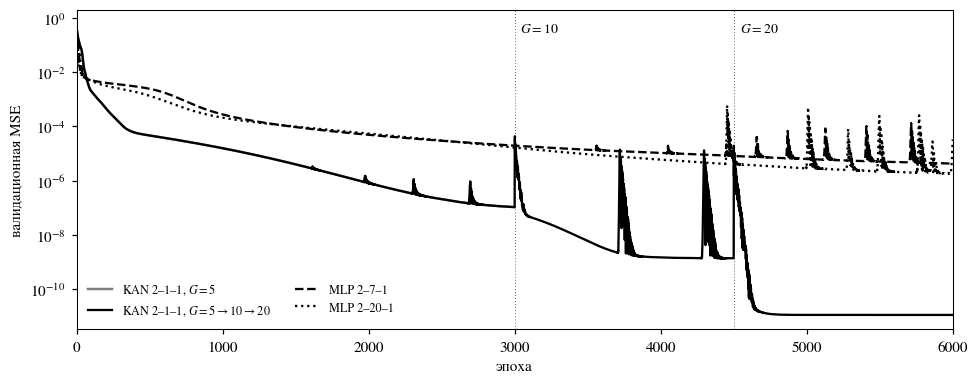

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for st, (label, h) in zip([STYLES[1], STYLES[0], STYLES[2], STYLES[3]], hists.items()):
    ax.semilogy(np.arange(1, len(h) + 1), np.array(h)[:, 1], label=label, **st)
for e in (3000, 4500): ax.axvline(e, color='black', lw=0.5, ls=(0, (1, 3)))
ax.text(3040, 0.3, '$G=10$', fontsize=9); ax.text(4540, 0.3, '$G=20$', fontsize=9)
ax.set_xlabel('эпоха'); ax.set_ylabel('валидационная MSE'); ax.set_xlim(0, 6000)
ax.legend(fontsize=8, ncol=2, loc='lower left')
fig.tight_layout(); fig.savefig(f'{RES_DIR}/history.png', dpi=200); plt.show()

Первые 3000 эпох двух вариантов KAN совпадают (одинаковые начальные значения и настройки), поэтому серая кривая скрыта под чёрной.

Внутри диапазона обучения сеть KAN с 30 параметрами точнее перцептрона с 29 параметрами примерно в 8 раз, а после уточнения сетки — почти в 500 раз: зависимость (4.32) имеет точное представление с одной ветвью, и сеть 2–1–1 способна его найти. Всплески на кривых возникают после уточнения сетки и при больших шагах вблизи минимума; на итог они не влияют, так как сохраняется лучшее по валидации состояние. Эпоха KAN заметно дороже эпохи перцептрона — это цена вычисления сплайнов.

<a id="s5"></a>
## 5. Символизация функций на связях (п. 4.4.5)

Для функции $\phi_{1,1,1}$ подбираем $\alpha\,g(u)+\eta$ для нескольких элементарных функций $g$ и сравниваем коэффициенты детерминации (4.29).

In [10]:
net = models['KAN 2–1–1, $G=5\\to10\\to20$']
L1, L2 = net.layers
z = np.linspace(-1, 1, 401)
u, v = 0.1 + 0.45 * (z + 1), 1 + 0.2 * z                     # обратное преобразование (4.33)
p1, p2 = L1.edge(0, 0, z), L1.edge(0, 1, z)

def fit_affine(f, g):
    A = np.stack([g, np.ones_like(g)], axis=1)
    coef = np.linalg.lstsq(A, f, rcond=None)[0]
    return coef, 1 - np.sum((f - A @ coef) ** 2) / np.sum((f - f.mean()) ** 2)

cands = [('$u$', u), ('$u^2$', u ** 2), (r'$\sqrt{u}$', np.sqrt(u)), ('$e^u$', np.exp(u)), (r'$\ln u$', np.log(u))]
r2s = [fit_affine(p1, gv)[1] for _, gv in cands]
display(Markdown('**Таблица 4.4.** Коэффициент детерминации при символизации функции $\\phi_{1,1,1}$\n\n'
    '| $g(u)$ | ' + ' | '.join(n for n, _ in cands) + ' |\n|' + '---|' * (len(cands) + 1) + '\n| $R^2$ | '
    + ' | '.join((f'**{r:.10f}**' if r == max(r2s) else f'{r:.4f}').replace('.', ',') for r in r2s) + ' |'))

(a1, b1), _ = fit_affine(p1, np.log(u))
(a2, b2), r2v = fit_affine(p2, np.log(v))
h_tr = L1.forward(D['train'][0])[:, 0]
H = np.linspace(h_tr.min(), h_tr.max(), 401); po = L2.edge(0, 0, H)
(alpha, beta), r2o = fit_affine(po, np.exp(H / a1))
r2f = lambda r: f'{r:.10f}'.replace('.', ',')
display(Markdown(f'''
| Связь | Подобранная функция | $R^2$ |
|---|---|---|
| $\\phi_{{1,1,1}}(u)$ | $a_1\\ln u+b_1$, $a_1={a1:.4f}$ | {r2f(r2s[-1])} |
| $\\phi_{{1,1,2}}(v)$ | $a_2\\ln v+b_2$, $a_2={a2:.4f}$ | {r2f(r2v)} |
| $\\phi_{{2,1,1}}(h)$ | $\\alpha e^{{h/a_1}}+\\beta$, $\\alpha={alpha:.4f}$, $\\beta\\approx 0$ | {r2f(r2o)} |

Отношение $a_2/a_1={a2 / a1:.4f}$; пример 4.6 предсказывает ровно $-2$.
'''.replace('0.', '0{,}').replace('1.', '1{,}').replace('2.', '2{,}').replace('5.', '5{,}')))

**Таблица 4.4.** Коэффициент детерминации при символизации функции $\phi_{1,1,1}$

| $g(u)$ | $u$ | $u^2$ | $\sqrt{u}$ | $e^u$ | $\ln u$ |
|---|---|---|---|---|---|
| $R^2$ | 0,9271 | 0,7914 | 0,9791 | 0,8614 | **0,9999999980** |


| Связь | Подобранная функция | $R^2$ |
|---|---|---|
| $\phi_{1,1,1}(u)$ | $a_1\ln u+b_1$, $a_1=0{,}5859$ | 0,9999999980 |
| $\phi_{1,1,2}(v)$ | $a_2\ln v+b_2$, $a_2=-1{,}1717$ | 1,0000000000 |
| $\phi_{2,1,1}(h)$ | $\alpha e^{h/a_1}+\beta$, $\alpha=0{,}5457$, $\beta\approx 0$ | 0,9999999999 |

Отношение $a_2/a_1=-2{,}0000$; пример 4.6 предсказывает ровно $-2$.


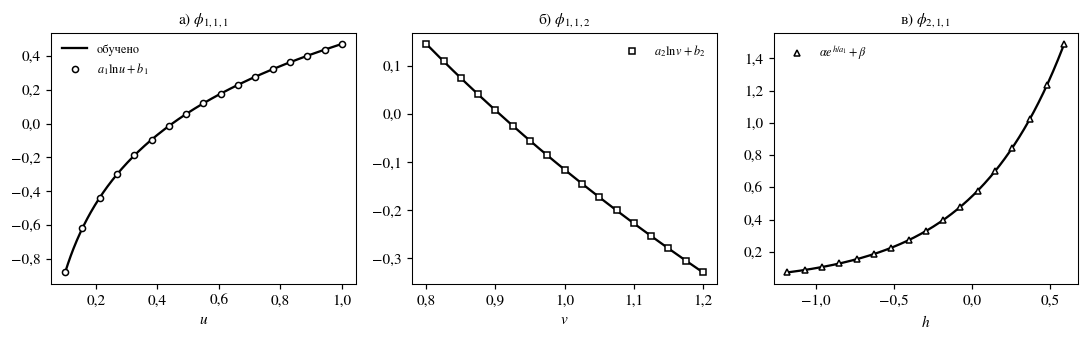

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
sel = slice(0, None, 25)
axs[0].plot(u, p1, 'k-', label='обучено'); axs[0].plot(u[sel], (a1 * np.log(u) + b1)[sel], 'o', mfc='white', mec='black', ms=4, label=r'$a_1\ln u+b_1$')
axs[1].plot(v, p2, 'k-'); axs[1].plot(v[sel], (a2 * np.log(v) + b2)[sel], 's', mfc='white', mec='black', ms=3.5, label=r'$a_2\ln v+b_2$')
axs[2].plot(H, po, 'k-'); axs[2].plot(H[sel], (alpha * np.exp(H / a1) + beta)[sel], '^', mfc='white', mec='black', ms=4, label=r'$\alpha e^{h/a_1}+\beta$')
for ax, lab, ttl in zip(axs, ['$u$', '$v$', '$h$'], [r'а) $\phi_{1,1,1}$', r'б) $\phi_{1,1,2}$', r'в) $\phi_{2,1,1}$']):
    ax.set_xlabel(lab); ax.set_title(ttl, fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f'{RES_DIR}/edges.png', dpi=200); plt.show()

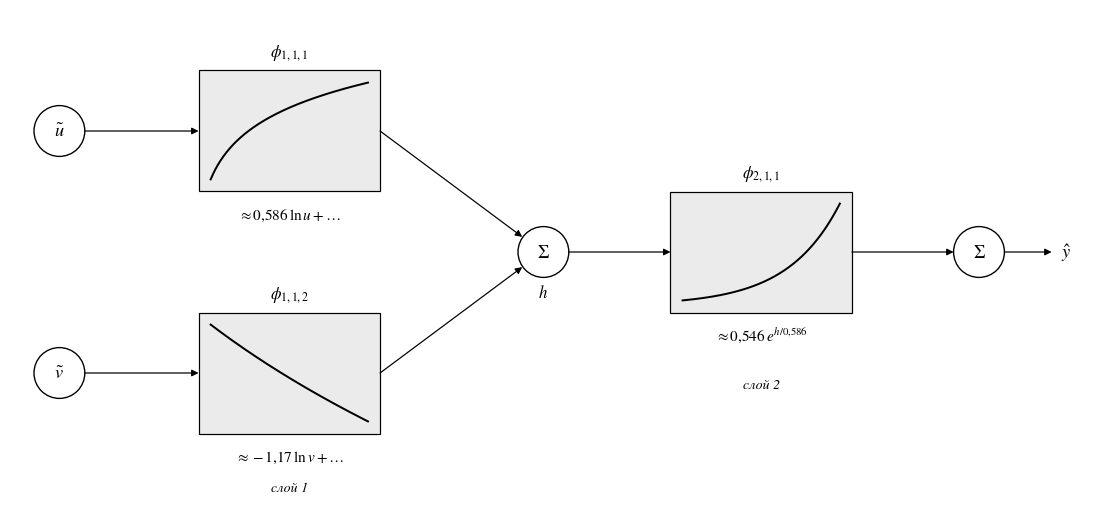

In [12]:
def _arrow(ax, x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=9, lw=0.8, color='black', shrinkA=0, shrinkB=0))
def _node(ax, x, y, text):
    ax.add_patch(Circle((x, y), 0.42, fc='white', ec='black', lw=0.9)); ax.text(x, y, text, ha='center', va='center', fontsize=12)
def _edge(ax, cx, cy, zz, phi, title, sym, w=3.0, h=2.0):
    ax.add_patch(Rectangle((cx - w / 2, cy - h / 2), w, h, fc=GREY, ec='black', lw=0.8))
    yn = (phi - phi.min()) / np.ptp(phi)
    ax.plot(cx - w / 2 + 0.2 + (zz - zz.min()) / np.ptp(zz) * (w - 0.4), cy - h / 2 + 0.2 + yn * (h - 0.4), 'k-', lw=1.3)
    ax.text(cx, cy + h / 2 + 0.25, title, ha='center', fontsize=11); ax.text(cx, cy - h / 2 - 0.45, sym, ha='center', fontsize=10)
mn = lambda v_, d=3: f'{v_:.{d}g}'.replace('.', '{,}')

fig = plt.figure(figsize=(10, 4.4))
ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 18); ax.set_ylim(0, 8); ax.set_aspect('equal'); ax.axis('off')
_node(ax, 0.8, 6.0, r'$\tilde u$'); _node(ax, 0.8, 2.0, r'$\tilde v$')
_edge(ax, 4.6, 6.0, u, p1, r'$\phi_{1,1,1}$', rf'$\approx {mn(a1)}\,\ln u+\ldots$')
_edge(ax, 4.6, 2.0, v, p2, r'$\phi_{1,1,2}$', rf'$\approx {mn(a2)}\,\ln v+\ldots$')
_arrow(ax, 1.22, 6.0, 3.1, 6.0); _arrow(ax, 1.22, 2.0, 3.1, 2.0)
_node(ax, 8.8, 4.0, r'$\Sigma$'); ax.text(8.8, 3.25, '$h$', ha='center', fontsize=11)
_arrow(ax, 6.1, 6.0, 8.45, 4.25); _arrow(ax, 6.1, 2.0, 8.45, 3.75)
_edge(ax, 12.4, 4.0, H, po, r'$\phi_{2,1,1}$', rf'$\approx {mn(alpha)}\,e^{{h/{mn(a1)}}}$')
_arrow(ax, 9.22, 4.0, 10.9, 4.0)
_node(ax, 16.0, 4.0, r'$\Sigma$'); _arrow(ax, 13.9, 4.0, 15.58, 4.0); _arrow(ax, 16.42, 4.0, 17.2, 4.0)
ax.text(17.35, 4.0, r'$\hat y$', va='center', fontsize=12)
ax.text(4.6, 0.05, 'слой 1', ha='center', fontsize=9, style='italic'); ax.text(12.4, 1.75, 'слой 2', ha='center', fontsize=9, style='italic')
fig.savefig(f'{RES_DIR}/network.png', dpi=200, bbox_inches='tight'); plt.show()

После символизации сеть превращается в формулу $\hat y=\alpha\exp\big((a_1\ln u+a_2\ln v+b_1+b_2)/a_1\big)+\beta$. При $a_2/a_1=-2$ и $\beta\approx0$ она совпадает с (4.32) с точностью до постоянного множителя: сеть, получившая только числа, восстановила структуру формулы расходомера.

<a id="s6"></a>
## 6. Экстраполяция (п. 4.4.6)

Вне сетки финитные B-сплайны равны нулю, и функция на связи сводится к $w_b\,\mathrm{SiLU}(x)$. Сравним это с **линейным продолжением** функций на связях по касательной в граничных точках.

| Модель | RMSE экстр., нули | RMSE экстр., лин. прод. | Макс. экстр., нули | Макс. экстр., лин. прод. | RMSE тест, лин. прод. |
|---|---|---|---|---|---|
| KAN 2–1–1, $G=5$ | 0,0307 | 0,0216 | 0,0814 | 0,0557 | $2{,}09\cdot10^{-4}$ |
| KAN 2–1–1, $G=5\to10\to20$ | 0,182 | 0,0119 | 0,361 | 0,0339 | $3{,}19\cdot10^{-6}$ |


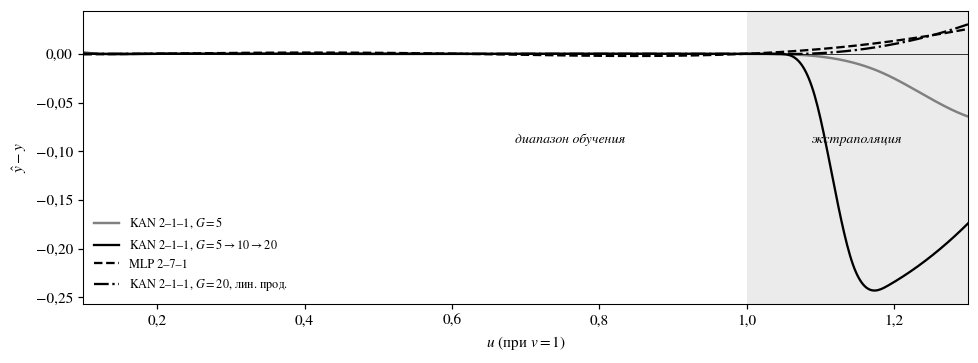

In [13]:
rows = ''
for label in ['KAN 2–1–1, $G=5$', 'KAN 2–1–1, $G=5\\to10\\to20$']:
    m = models[label]
    ez = metrics(m, *D['extra'][:2]); m.set_extension('linear')
    el, tl = metrics(m, *D['extra'][:2]), metrics(m, *D['test'][:2]); m.set_extension('zero')
    rows += f'| {label} | {num(ez[0])} | {num(el[0])} | {num(ez[2])} | {num(el[2])} | {sci(tl[0])} |\n'
display(Markdown('| Модель | RMSE экстр., нули | RMSE экстр., лин. прод. | Макс. экстр., нули | Макс. экстр., лин. прод. | RMSE тест, лин. прод. |\n'
                 '|---|---|---|---|---|---|\n' + rows))

uu = np.linspace(0.1, 1.3, 601); vv = np.ones_like(uu); Xc, yc = normalize(uu, vv), target(uu, vv)[:, 0]
curves = {lab: models[lab].predict(Xc)[:, 0] - yc for lab in ['KAN 2–1–1, $G=5$', 'KAN 2–1–1, $G=5\\to10\\to20$', 'MLP 2–7–1']}
net.set_extension('linear'); curves['KAN 2–1–1, $G=20$, лин. прод.'] = net.predict(Xc)[:, 0] - yc; net.set_extension('zero')

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.axvspan(1.0, 1.3, color=GREY, lw=0)
for st, (lab, e) in zip([STYLES[1], STYLES[0], STYLES[2], STYLES[4]], curves.items()):
    ax.plot(uu, e, label=lab, **st)
ax.axhline(0, color='black', lw=0.5); ax.set_xlim(0.1, 1.3)
ax.text(0.55, 0.55, 'диапазон обучения', transform=ax.transAxes, ha='center', style='italic', fontsize=9)
ax.text(1.15, 0.55, 'экстраполяция', transform=ax.get_xaxis_transform(), ha='center', style='italic', fontsize=9)
ax.set_xlabel('$u$ (при $v=1$)'); ax.set_ylabel(r'$\hat y-y$'); ax.legend(fontsize=8, loc='lower left')
fig.tight_layout(); fig.savefig(f'{RES_DIR}/extrapolation.png', dpi=200); plt.show()

Плохая экстраполяция — свойство выбранной параметризации (финитные сплайны), а не самого принципа суперпозиции: линейное продолжение уменьшает ошибку сети с уточнённой сеткой более чем на порядок. Но и оно остаётся лишь предположением о поведении функции за пределами данных. Правильно экстраполирует только найденная формула — если она действительно совпадает с физическим законом.

<a id="s7"></a>
## 7. Опыт с шумом (п. 4.4.6)

К целям обучающей и валидационной выборок добавляется равномерный шум $U(-\delta/2,\delta/2)$ со стандартным отклонением $\delta/\sqrt{12}$; тестовая выборка остаётся без шума.

In [14]:
rows_noise = []
NOISE_PLANS = [('KAN 2–1–1, $G=5$', 'KAN 2-1-1 G=5', [dict(epochs=3000, lr=0.01)]),
               ('KAN 2–1–1, $G=5\\to10\\to20$', 'KAN 2-1-1 G=5', STAGED),
               ('KAN 2–1–1, $G=5\\to50$', 'KAN 2-1-1 G=5', [dict(epochs=3000, lr=0.01), dict(G=50, epochs=3000, lr=0.003)]),
               ('MLP 2–7–1', 'MLP 2-7-1', [dict(epochs=6000, lr=0.01)])]
res = {}
for delta in (0.01, 0.05):
    rng = np.random.default_rng(SEED_NOISE)
    ytr = D['train'][1] + rng.uniform(-delta / 2, delta / 2, D['train'][1].shape)
    yva = D['val'][1] + rng.uniform(-delta / 2, delta / 2, D['val'][1].shape)
    Dn = dict(D, train=(D['train'][0], ytr), val=(D['val'][0], yva))
    for label, init_name, stages in NOISE_PLANS:
        m, _ = run_model(init_name, Dn, stages, [])
        tr = np.sqrt(np.mean((m.forward(Dn['train'][0]) - ytr) ** 2)); te = metrics(m, *D['test'][:2])[0]
        res[(label, delta)] = (m.n_params(), tr, te); rows_noise.append((delta, label, m.n_params(), tr, te))

f5 = lambda v_: f'{v_:.5f}'.replace('.', ',')
display(Markdown('**Таблица 4.5.** RMSE на обучающей выборке (с шумом) и на тестовой (без шума)\n\n'
    '| Модель | Парам. | $\\delta=0{,}01$: обучение | $\\delta=0{,}01$: тест | $\\delta=0{,}05$: обучение | $\\delta=0{,}05$: тест |\n'
    '|---|---|---|---|---|---|\n' + ''.join(
    f'| {lab} | {res[(lab, 0.01)][0]} | {f5(res[(lab, 0.01)][1])} | {f5(res[(lab, 0.01)][2])} | {f5(res[(lab, 0.05)][1])} | {f5(res[(lab, 0.05)][2])} |\n'
    for lab, _, _ in NOISE_PLANS)
    + f'\nСтандартное отклонение шума: {f5(0.01 / np.sqrt(12))} и {f5(0.05 / np.sqrt(12))}.'))

**Таблица 4.5.** RMSE на обучающей выборке (с шумом) и на тестовой (без шума)

| Модель | Парам. | $\delta=0{,}01$: обучение | $\delta=0{,}01$: тест | $\delta=0{,}05$: обучение | $\delta=0{,}05$: тест |
|---|---|---|---|---|---|
| KAN 2–1–1, $G=5$ | 30 | 0,00284 | 0,00086 | 0,01361 | 0,00366 |
| KAN 2–1–1, $G=5\to10\to20$ | 75 | 0,00285 | 0,00115 | 0,01333 | 0,00414 |
| KAN 2–1–1, $G=5\to50$ | 165 | 0,00230 | 0,00219 | 0,01298 | 0,00614 |
| MLP 2–7–1 | 29 | 0,00337 | 0,00179 | 0,01405 | 0,00431 |

Стандартное отклонение шума: 0,00289 и 0,01443.

При $G=50$ ошибка на обучающей выборке опускается ниже стандартного отклонения шума: сеть начинает воспроизводить случайные отклонения, а ошибка на чистом тесте растёт — это переобучение (глава 6). Грубая сетка $G=5$ работает как сглаживающий фильтр. Число узлов следует выбирать по валидационной ошибке.

<a id="s8"></a>
## 8. Сохранение результатов и отчёт (п. 4.4.7)

In [15]:
strip = lambda s: s.replace('$', '').replace('\\to', '→')
write_csv(f'{RES_DIR}/metrics.csv', ['model', 'params', 'rmse_test', 'mae_test', 'max_test', 'rmse_extra', 'mae_extra', 'max_extra', 'seconds'],
          [(strip(r[0]), r[1], *map(float, r[2:])) for r in rows_metrics])
write_csv(f'{RES_DIR}/history.csv', ['model', 'epoch', 'mse_train', 'mse_val'],
          [(strip(lab), n + 1, float(a), float(b)) for lab, h in hists.items() for n, (a, b) in enumerate(h)])
write_csv(f'{RES_DIR}/symbolic.csv', ['a1', 'b1', 'a2', 'b2', 'alpha', 'beta'],
          [tuple(map(float, (a1, b1, a2, b2, alpha, beta)))])
write_csv(f'{RES_DIR}/noise.csv', ['delta', 'model', 'params', 'rmse_train', 'rmse_test'],
          [(float(d), strip(l), p, float(a), float(b)) for d, l, p, a, b in rows_noise])
print('сохранено в', os.path.abspath(RES_DIR), ':', sorted(os.listdir(RES_DIR)))

сохранено в C:\Code\ML_tutorials\Глава 4\results : ['bsplines.png', 'edges.png', 'extrapolation.png', 'history.csv', 'history.png', 'metrics.csv', 'network.png', 'noise.csv', 'symbolic.csv']


**Обязательная часть отчёта:**
- графики B-сплайнов и проверка разбиения единицы (раздел 2);
- схема сети 2–2–1 для произведения и оценка её точности (раздел 3);
- архитектура 2–1–1, число параметров по (4.21) и (4.22), настройки обучения, кривые обучения, таблица метрик (раздел 4);
- графики функций на связях и результаты символизации (раздел 5);
- опыты с экстраполяцией и шумом (разделы 6–7).

В выводах отделите аналитические утверждения (пример 4.6, вложенность пространств сплайнов) от результатов конкретного запуска и укажите диапазон, в котором справедливы выводы о точности.

**Задания повышенной сложности.** Обучите сеть 2–5–1 на функции $\exp(\sin\pi x+y^2)$ и выполните прореживание (разбор этой функции — в блокноте `KAN_примеры.ipynb`); замените B-сплайны на связях тригонометрическими суммами (3.23); для модели датчика давления из примера 4.4 сравните аддитивную сеть 2–1 с сетью 2–2–1.